In [17]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, BatchNormalization, Dropout, Flatten, Dense,Input

In [10]:
data_dir = r"C:\Users\geetb\Downloads\PetImages"

# Data PreProcessing

In [24]:
datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2  
)

In [12]:
train_generator = datagen.flow_from_directory(
    data_dir,
    target_size=(150, 150),
    batch_size=32,
    class_mode='binary',
    subset='training'
)

Found 20000 images belonging to 2 classes.


In [14]:
validation_generator = datagen.flow_from_directory(
    data_dir,
    target_size=(150, 150),
    batch_size=32,
    class_mode='binary',
    subset='validation'
)

Found 4998 images belonging to 2 classes.


# CNN Model

In [18]:
model = Sequential()

model.add(Input(shape=(150, 150, 3)))

model.add(Conv2D(32, (3,3), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(2,2))

model.add(Conv2D(64, (3,3), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(2,2))

model.add(Conv2D(128, (3,3), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(2,2))

model.add(Flatten())

model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))

model.add(Dense(1, activation='sigmoid'))

In [19]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Training 

In [20]:
history = model.fit(
    train_generator,
    epochs=10,
    validation_data=validation_generator
)

Epoch 1/10
201/625 ━━━━━━━━━━━━━━━━━━━━ 7:05 1s/step - accuracy: 0.5686 - loss: 3.4882

C:\Users\geetb\anaconda3\Lib\site-packages\PIL\TiffImagePlugin.py:949: UserWarning: Truncated File Read
  warnings.warn(str(msg))


625/625 ━━━━━━━━━━━━━━━━━━━━ 819s 1s/step - accuracy: 0.6363 - loss: 1.0067 - val_accuracy: 0.6895 - val_loss: 0.5961
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 1552s 2s/step - accuracy: 0.7315 - loss: 0.5425 - val_accuracy: 0.7591 - val_loss: 0.5145
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 738s 1s/step - accuracy: 0.7764 - loss: 0.4695 - val_accuracy: 0.7603 - val_loss: 0.4771
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 746s 1s/step - accuracy: 0.8109 - loss: 0.4115 - val_accuracy: 0.7653 - val_loss: 0.4640
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 734s 1s/step - accuracy: 0.8415 - loss: 0.3583 - val_accuracy: 0.7599 - val_loss: 0.6412
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 729s 1s/step - accuracy: 0.8645 - loss: 0.3098 - val_accuracy: 0.8107 - val_loss: 0.4041
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 736s 1s/step - accuracy: 0.8885 - loss: 0.2516 - val_accuracy: 0.8305 - val_loss: 0.5119
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 787s 1s/step - accuracy: 0.9079 - loss: 0.2203 - val_accuracy: 0.76

In [25]:
model.save("cat_dog_cnn_model.keras")

# Evaluation

In [23]:
loss, accuracy = model.evaluate(validation_generator)
print(f"\nValidation Accuracy: {accuracy * 100:.2f}%")

157/157 ━━━━━━━━━━━━━━━━━━━━ 44s 280ms/step - accuracy: 0.7673 - loss: 1.6316

Validation Accuracy: 76.73%


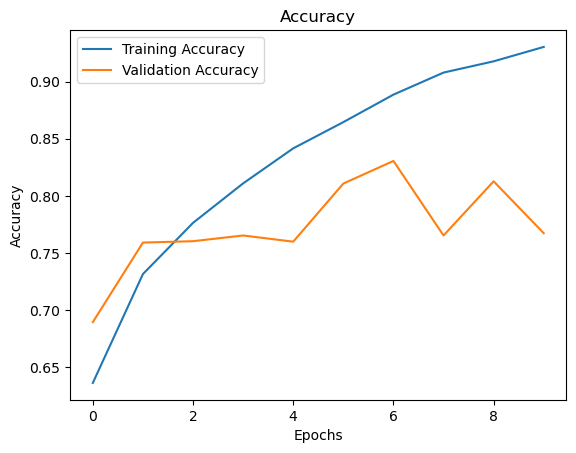

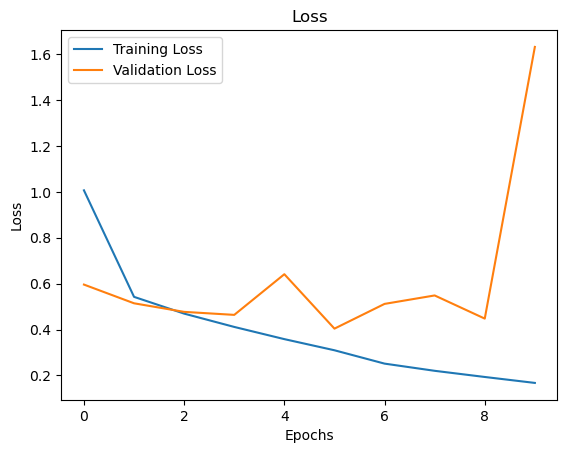

In [27]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


plt.figure()
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()